In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

TensorFlow version:  2.22.0-rc0


In [3]:
base_dir = 'data'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'validation')

batch_size = 32 # Model will process 32 at a time
img_height = 150
img_width = 150
epochs = 10


In [ ]:
# data: https://www.kaggle.com/datasets/tongpython/cat-and-dog
# /data/train/cats /data/train/dogs /data/validation/cats /data/validation/dogs
train_datagen = ImageDataGenerator(
    rescale=1./255, # normalizes image vals
    rotation_range=20, # rotate up to 20deg
    width_shift_range=0.1, # shift slightly in wid
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.2, # zoom in up to 20%
    horizontal_flip=True, # randomly flip
    fill_mode='nearest', # filled gaps from transformations
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(img_height, img_width), # resize all imgs to same dim
    batch_size=batch_size,
    class_mode='binary', # binary, cats or dogs
    shuffle=True,
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='binary',
)

Found 8005 images belonging to 2 classes.
Found 2023 images belonging to 2 classes.


In [6]:
model = keras.Sequential([
    keras.Input(shape=(img_height, img_width, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'), # applys 32 filters, each of size 3x3 to input
    layers.MaxPool2D((2,2)), # reduces spacial dim by taking max val in 2x2 window

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPool2D((2,2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPool2D((2,2)),

    layers.Flatten(), # convert 2d map to 1d vec
    layers.Dense(128, activation='relu'),
    
    layers.Dropout(0.5), # prevent overfitting
    layers.Dense(1, activation='sigmoid') # 1 unit for binary classification
        
])

In [7]:
model.compile(
    loss='binary_crossentropy', # loss func for binary classification
    optimizer='adam',
    metrics=['accuracy'],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=val_generator
) 

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 59s 230ms/step - accuracy: 0.5365 - loss: 0.6957 - val_accuracy: 0.6317 - val_loss: 0.6680
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 58s 230ms/step - accuracy: 0.6130 - loss: 0.6635 - val_accuracy: 0.6421 - val_loss: 0.6412
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 64s 254ms/step - accuracy: 0.6481 - loss: 0.6390 - val_accuracy: 0.6772 - val_loss: 0.6191
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 56s 223ms/step - accuracy: 0.6723 - loss: 0.6172 - val_accuracy: 0.7019 - val_loss: 0.5968
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 63s 250ms/step - accuracy: 0.6800 - loss: 0.6012 - val_accuracy: 0.7395 - val_loss: 0.5528
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 56s 223ms/step - accuracy: 0.7014 - loss: 0.5708 - val_accuracy: 0.7252 - val_loss: 0.5588
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 57s 225ms/step - accuracy: 0.7229 - loss: 0.5511 - val_accuracy: 0.7578 - val_loss: 0.5125
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 57s 228ms/step - accuracy: 0.7344 - loss: 0

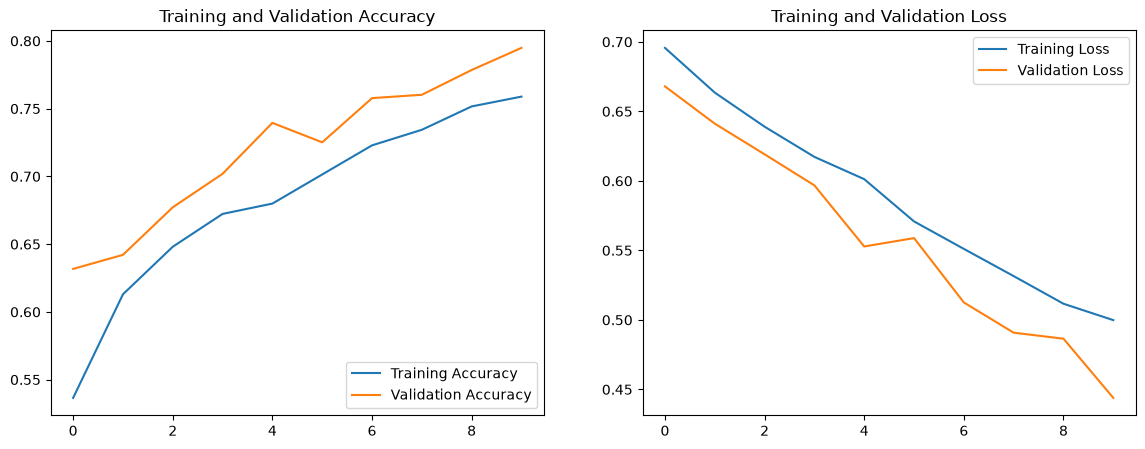

In [10]:
# acc & loss -> accuracy and loss on training data
# val_acc & val_loss -> accuracy and loss on validation data
# https://medium.com/@machinepoet/analyze-loss-vs-val-loss-and-accuracy-vs-val-accuracy-292891ae931f
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(14,5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


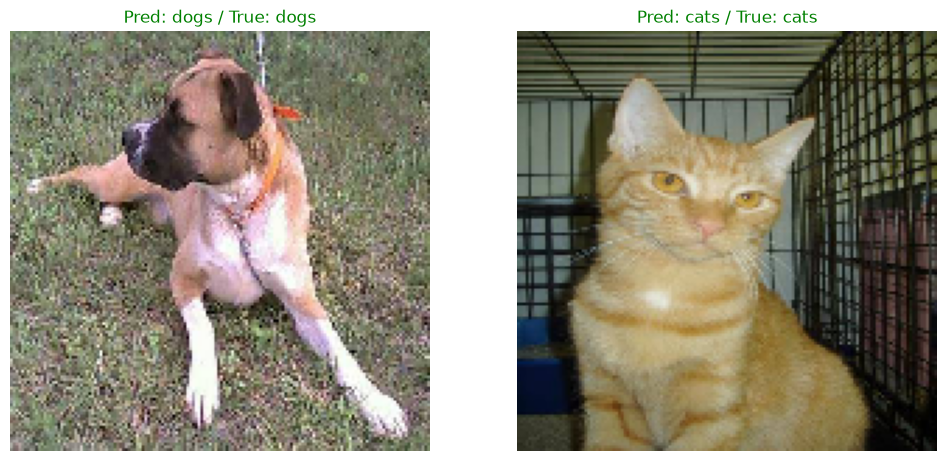

In [15]:
import matplotlib.image as mpimg
import random

# pick some validation images randomly
class_labels = list(train_generator.class_indices.keys())

# get a batch of validation images
val_images, val_labels = next(val_generator)

# Randomly select from this batch
num_test_images = 2
plt.figure(figsize=(12, 12))

for i in range(num_test_images):
    plt.subplot(2, 2, i + 1)
    random_idx = random.randint(0, len(val_images) - 1)
    image = val_images[random_idx]
    true_label = val_labels[random_idx]

    pred = model.predict(image[np.newaxis, ...])[0][0]
    predicted_label = 1 if pred > 0.5 else 0

    plt.imshow(image)
    title_color = 'green' if predicted_label == true_label else 'red'
    plt.title(f"Pred: {class_labels[predicted_label]} / True: {class_labels[int(true_label)]}", color=title_color)
    plt.axis('off')
plt.show()

In [16]:
model.save('cat_dog_classifier.h5')
print("Model saved as cat_dog_classifier.h5")

Model saved as cat_dog_classifier.h5
